<a href="https://colab.research.google.com/github/akshin-kuvshin/numerical-methods/blob/main/lab2/lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №2. Многочлены Лагранжа, Ньютона и схема Эйткена

## Выполнил: Данила Аксёнов, гр. 932420

## Вариант: 1

<hr>

## **Задание 2**

1) Найти приближенное значение функции в точке $ x_* $ по таблице значений $ (x_i, y_i) $, используя многочлен Лагранжа;

2) Построить график многочлена Лагранжа с табличными значениями и график вычислительной погрешности;

3) Считая, что табличные значения заданы с верными знаками, оценить неустранимую погрешность результата.

## Решение:

In [1]:
import numpy as np
from matplotlib import pyplot as plt
print('Setup completed')

Setup completed


### Исходные данные:

In [2]:
x = np.array([0.35, 0.48, 0.97, 1.08, 1.18, 1.35])
y = np.array([1.419, 1.616, 2.637, 2.944, 3.254, 4.119])
n = len(x) # == len(y)

x_star = 0.58

### Аппроксимируем значение функции в точке $ x_* $:

In [3]:
def f_lagrange(x_0):
    y_0 = 0.

    for i in range(n):
        numerator = 1.
        denominator = 1.
        for j in range(n):
            if i == j:
                continue
            numerator *= (x_0 - x[j])
            denominator *= (x[i] - x[j])
        l_i = numerator / denominator
        y_0 += y[i] * l_i

    return y_0

In [4]:
y_star = f_lagrange(x_star)
y_star

np.float64(1.7392512750270868)

Получили $ y_* \approx 1.73925128 $.

### Строим график интерполяционного многочлена Лагранжа:

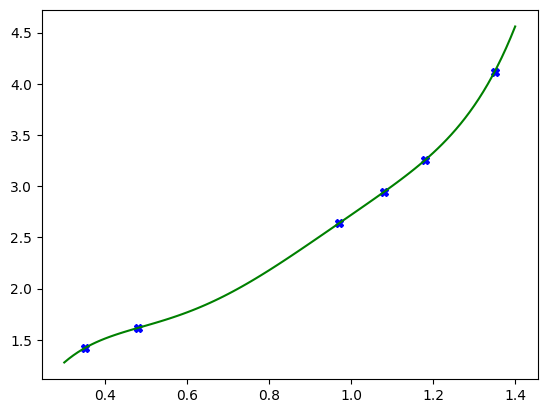

In [5]:
x_min = 0.3
x_max = 1.4
m = 100

for x_i, y_i in zip(x, y):
    plt.plot(x_i, y_i, 'X', color='blue')

x_ = np.linspace(x_min, x_max, num=m)
y_ = np.array(list(map(f_lagrange, x_)))
plt.plot(x_, y_, '-', color='green')

plt.show()

### Считаем неустранимую погрешность результата:

Все числа будем хранить в кортежах следующего вида: $ (x, \Delta x*, \delta x*) $.

In [6]:
# получить абсолютную и относительную погрешность узла x[i]
def get_x_error(x_i):
    n = 3 if x_i > 1 else 2
    m = 0 if x_i > 1 else -1
    k = m - n + 1
    abs_error = 0.5 * 10 ** k
    rel_error = abs_error / abs(x_i)
    return (x_i, abs_error, rel_error)

In [7]:
# получить абсолютную и относительную погрешность значения в узле y[i]
def get_y_error(y_i):
    n = 4
    m = 0
    k = m - n + 1
    abs_error = 0.5 * 10 ** k
    rel_error = abs_error / abs(y_i)
    return (y_i, abs_error, rel_error)

In [8]:
# получить абсолютную и относительную погрешность суммы многих слагаемых
# ts = [t_1, t_2, ..., t_n]
# t_1 + t_2 + ... + t_n
def get_sum_error(ts):
    res = sum(t[0] for t in ts)
    abs_error = sum(t[1] for t in ts)
    rel_error = max(t[2] for t in ts)
    return (res, abs_error, rel_error)

In [9]:
# получить абсолютную и относительную погрешность разности
# t1 - t2
def get_diff_error(t1, t2):
    res = t1[0] - t2[0]
    abs_error = t1[1] + t2[1]
    rel_error = (abs(t1[0]) * t1[2] + abs(t2[0]) * t2[2]) / abs(res)
    return (res, abs_error, rel_error)

In [10]:
# получить абсолютную и относительную погрешность произведения многих сомножителей
# ts = [t_1, t_2, ..., t_n]
# t_1 * t_2 * ... * t_n
def get_prod_error(ts):
    res = 1.
    for t in ts:
        res *= t[0]
    rel_error = sum(t[2] for t in ts)
    abs_error = abs(res) * rel_error
    return (res, abs_error, rel_error)

In [11]:
# получить абсолютную и относительную погрешность частного
# t1 / t2
def get_quotient_error(t1, t2):
    res = t1[0] / t2[0]
    abs_error = (t1[1] + abs(res) * t2[1]) / abs(t2[0])
    rel_error = t1[2] + t2[2]
    return (res, abs_error, rel_error)

In [12]:
x_error = np.array(list(map(get_x_error, x)))
y_error = np.array(list(map(get_y_error, y)))

def get_f_lagrange_inherent_error(x_0):
    x_0_error = get_x_error(x_0)

    y_0_elems_error = []

    for i in range(n):
        numerator_elems_error = []
        denominator_elems_error = []
        for j in range(n):
            if i == j:
                continue
            numerator_elems_error.append(get_diff_error(x_0_error, x_error[j]))
            denominator_elems_error.append(get_diff_error(x_error[i], x_error[j]))
        numerator_error = get_prod_error(numerator_elems_error)
        denominator_error = get_prod_error(denominator_elems_error)

        li_error = get_quotient_error(numerator_error, denominator_error)
        y_0_elems_error.append(get_prod_error((y_error[i], li_error)))
    y_0_error = get_sum_error(y_0_elems_error)

    return y_0_error

In [13]:
y_star_error = get_f_lagrange_inherent_error(x_star)
y_star_error

(np.float64(1.7392512750270868),
 np.float64(9.426493955965267),
 np.float64(0.45725422787057324))

Получили неутешительные результаты: $ \Delta_н \approx 9.42649396, \delta_н \approx 0.45725423 $.

Консультация с ИИ не помогла выявить ошибки в расчётном коде, которые, по моему мнению, приводят к такому большому значению.

### Строим график вычислительной погрешности интерполяции с помощью многочлена Лагранжа:

In [14]:
def get_f_lagrange_method_error(x_0):
    error = 0.

    for i in range(n):
        numerator = 1.
        denominator = 1.
        for j in range(n):
            if i == j:
                continue
            numerator *= (x_0 - x[j])
            denominator *= (x[i] - x[j])
        l_i = numerator / denominator
        error += y_error[i][1] * abs(l_i)

    return error

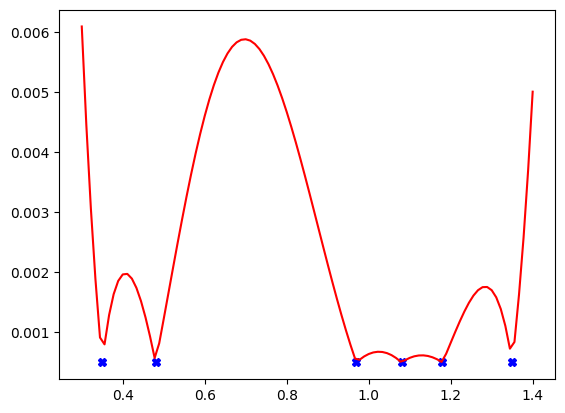

In [15]:
y_method_error = np.array(list(map(get_f_lagrange_method_error, x)))
for x_i, dy_i in zip(x, y_method_error):
    plt.plot(x_i, dy_i, 'X', color='blue')

y__method_error = np.array(list(map(get_f_lagrange_method_error, x_)))
plt.plot(x_, y__method_error, '-', color='red')

plt.show()

<hr>

## **Задание 3**

1) Найти приближенное значение функции в точке $ x_* $ по схеме Эйткена;

2) Оценить неустранимую погрешность результата.

## Решение:

### Аппроксимируем значение функции в точке $ x_* $:

In [26]:
# строим таблицу функций L(x)
L = []
for i in range(n):
    L.append([])
    for len_ in range(i + 2):
        if len_ < 2:
            L[i].append(lambda x_0: 0)
            continue
        if len_ == 2:
            L[i].append(lambda x_0, i_=i: (y[i_ - 1] * (x[i_] - x_0) - y[i_] * (x[i_ - 1] - x_0)) / (x[i_] - x[i_ - 1]))
            continue
        L[i].append(lambda x_0, i_=i, len__=len_: (L[i_ - 1][len__ - 1](x_0) * (x[i_] - x_0) - L[i_][len__ - 1](x_0) * (x[i_ - len__ + 1] - x_0)) / (x[i_] - x[i_ - len__ + 1]))

In [28]:
y_star = L[-1][-1](x_star)
y_star

np.float64(1.7392512750270879)

Снвоа получили $ y_* \approx 1.73925128 $.

Результат совпадает с результатом интерполяционного многочлена Лагранжа.